Best configuration:
Temperature = 4.0
Alpha       = 0.6
Accuracy    = 0.8749
Macro-F1    = 0.8517
Toxic-F1    = 0.7929


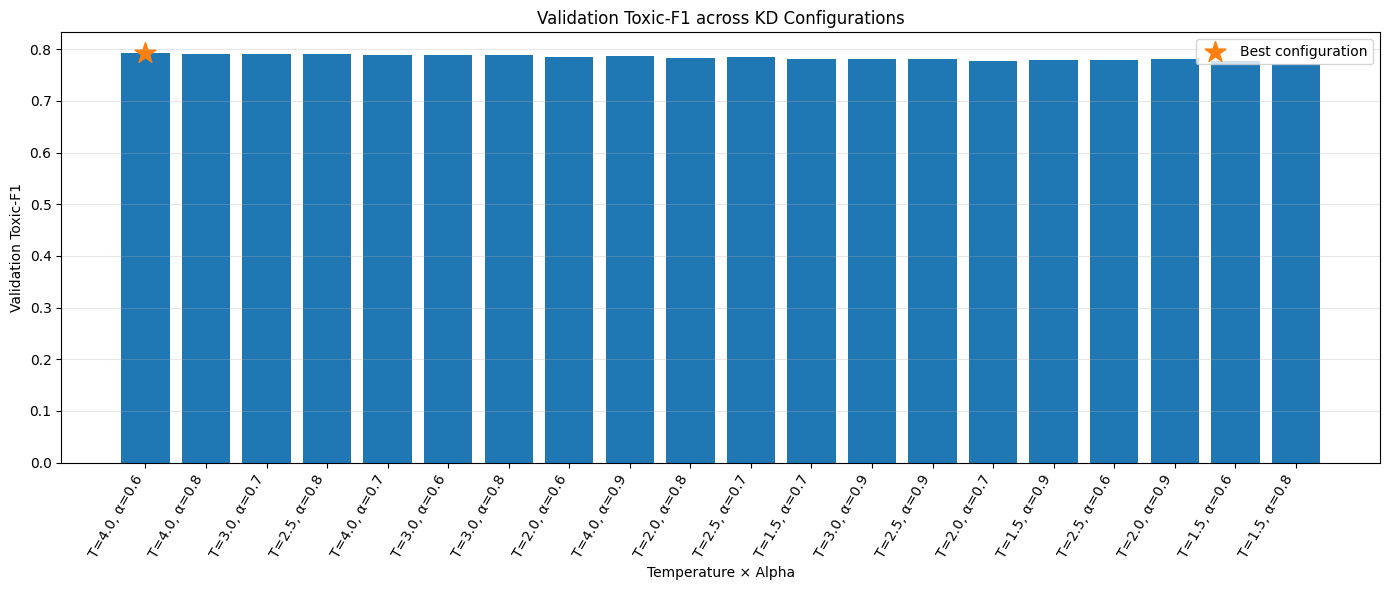

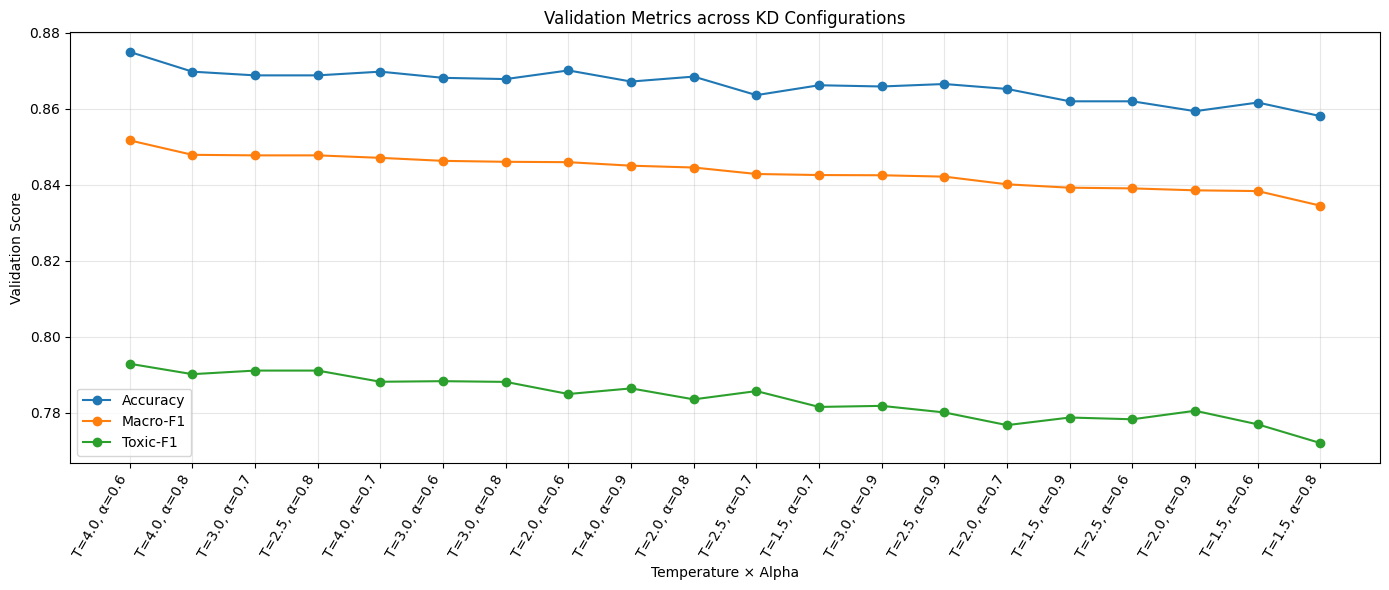

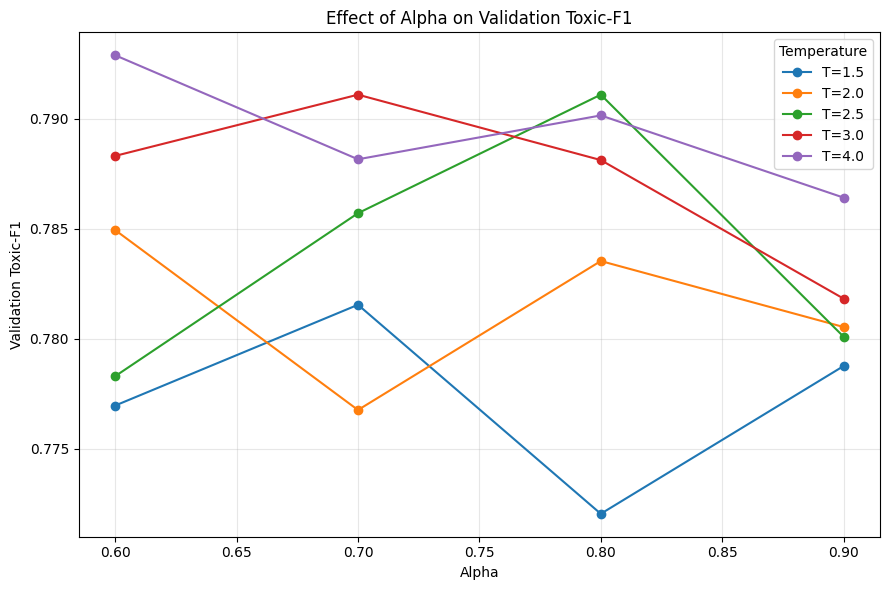

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# ==============================
# 1. Đọc file
# ==============================
df = pd.read_csv(r"kd_grid_results.csv")

# ==============================
# 2. Tìm cấu hình tốt nhất
# ==============================
best = df.loc[df["Val Toxic-F1"].idxmax()]

print("Best configuration:")
print(f"Temperature = {best['Temperature']}")
print(f"Alpha       = {best['Alpha']}")
print(f"Accuracy    = {best['Val Accuracy']:.4f}")
print(f"Macro-F1    = {best['Val Macro-F1']:.4f}")
print(f"Toxic-F1    = {best['Val Toxic-F1']:.4f}")

# ==============================
# 3. Tạo label cho từng config
# ==============================
df["Config"] = (
    "T=" + df["Temperature"].astype(str)
    + ", α=" + df["Alpha"].astype(str)
)

# =====================================================
# BIỂU ĐỒ 1: Toxic-F1 của từng Temperature × Alpha
# =====================================================

plt.figure(figsize=(14, 6))

plt.bar(
    df["Config"],
    df["Val Toxic-F1"]
)

plt.xlabel("Temperature × Alpha")
plt.ylabel("Validation Toxic-F1")
plt.title("Validation Toxic-F1 across KD Configurations")

plt.xticks(rotation=60, ha="right")

# Đánh dấu best
best_idx = df["Val Toxic-F1"].idxmax()

plt.scatter(
    best_idx,
    df.loc[best_idx, "Val Toxic-F1"],
    marker="*",
    s=250,
    label="Best configuration"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# =====================================================
# BIỂU ĐỒ 2: Accuracy / Macro-F1 / Toxic-F1
# =====================================================

plt.figure(figsize=(14, 6))

plt.plot(
    df["Config"],
    df["Val Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    df["Config"],
    df["Val Macro-F1"],
    marker="o",
    label="Macro-F1"
)

plt.plot(
    df["Config"],
    df["Val Toxic-F1"],
    marker="o",
    label="Toxic-F1"
)

plt.xlabel("Temperature × Alpha")
plt.ylabel("Validation Score")

plt.title("Validation Metrics across KD Configurations")

plt.xticks(rotation=60, ha="right")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# =====================================================
# BIỂU ĐỒ 3: Alpha → Toxic-F1 theo từng Temperature
# =====================================================

plt.figure(figsize=(9, 6))

for T in sorted(df["Temperature"].unique()):

    subset = df[df["Temperature"] == T].sort_values("Alpha")

    plt.plot(
        subset["Alpha"],
        subset["Val Toxic-F1"],
        marker="o",
        label=f"T={T}"
    )

plt.xlabel("Alpha")
plt.ylabel("Validation Toxic-F1")

plt.title("Effect of Alpha on Validation Toxic-F1")

plt.legend(title="Temperature")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

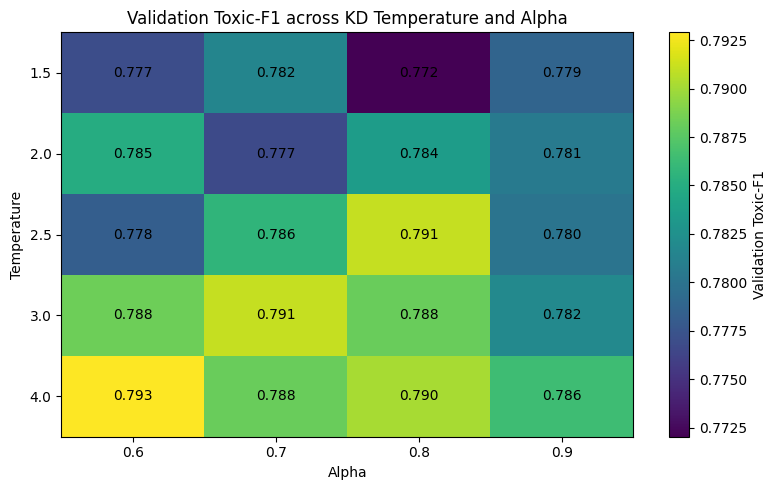

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r"kd_grid_results.csv")

# Tạo bảng:
# rows    = Temperature
# columns = Alpha
# values  = Toxic-F1
heatmap_data = df.pivot(
    index="Temperature",
    columns="Alpha",
    values="Val Toxic-F1"
)

plt.figure(figsize=(8, 5))

plt.imshow(
    heatmap_data,
    aspect="auto"
)

plt.colorbar(
    label="Validation Toxic-F1"
)

plt.xticks(
    range(len(heatmap_data.columns)),
    heatmap_data.columns
)

plt.yticks(
    range(len(heatmap_data.index)),
    heatmap_data.index
)

plt.xlabel("Alpha")
plt.ylabel("Temperature")

plt.title(
    "Validation Toxic-F1 across KD Temperature and Alpha"
)

# Hiển thị giá trị trong từng ô
for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):

        value = heatmap_data.iloc[i, j]

        plt.text(
            j,
            i,
            f"{value:.3f}",
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()